In [2]:
import pandas as pd
import os

print("Files in Colab:")
print(os.listdir("/content"))

Files in Colab:
['.config', '.ipynb_checkpoints', 'Unemployment_Rate_upto_11_2020.csv', 'Unemployment in India.csv', 'sample_data']


In [3]:

import pandas as pd

# Load both datasets
df1 = pd.read_csv("/content/Unemployment in India.csv")
df2 = pd.read_csv("/content/Unemployment_Rate_upto_11_2020.csv")

# Display dataset sizes
print("Dataset 1: Unemployment in India")
print("Shape:", df1.shape)
print("Columns:", df1.columns.tolist())
display(df1.head())

print("\nDataset 2: Unemployment Rate up to November 2020")
print("Shape:", df2.shape)
print("Columns:", df2.columns.tolist())
display(df2.head())


Dataset 1: Unemployment in India
Shape: (768, 7)
Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Dataset 2: Unemployment Rate up to November 2020
Shape: (267, 9)
Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [4]:

# Clean column names by removing extra spaces
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Convert date columns into proper date format
df1["Date"] = pd.to_datetime(df1["Date"], dayfirst=True, errors="coerce")
df2["Date"] = pd.to_datetime(df2["Date"], dayfirst=True, errors="coerce")

# Check missing values
print("Missing values in Dataset 1:")
print(df1.isnull().sum())

print("\nMissing values in Dataset 2:")
print(df2.isnull().sum())

# Display dataset information
print("\nDataset 1 information:")
df1.info()

print("\nDataset 2 information:")
df2.info()


Missing values in Dataset 1:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Missing values in Dataset 2:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

Dataset 1 information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count

In [5]:

# Check completely empty rows
print("Completely empty rows in Dataset 1:",
      df1.isnull().all(axis=1).sum())

# Remove rows where every column is empty
df1 = df1.dropna(how="all").copy()

# Remove any remaining rows missing important analysis values
df1 = df1.dropna(subset=[
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Area"
]).copy()

# Check the cleaned datasets
print("\nDataset 1 shape after cleaning:", df1.shape)
print("Dataset 2 shape:", df2.shape)

print("\nRemaining missing values in Dataset 1:")
print(df1.isnull().sum().sum())

print("\nRemaining missing values in Dataset 2:")
print(df2.isnull().sum().sum())


Completely empty rows in Dataset 1: 28

Dataset 1 shape after cleaning: (740, 7)
Dataset 2 shape: (267, 9)

Remaining missing values in Dataset 1:
0

Remaining missing values in Dataset 2:
0


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Load both CSV files again
df1 = pd.read_csv("/content/Unemployment in India.csv")
df2 = pd.read_csv("/content/Unemployment_Rate_upto_11_2020.csv")

# Clean column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Convert dates
df1["Date"] = pd.to_datetime(
    df1["Date"], dayfirst=True, errors="coerce"
)
df2["Date"] = pd.to_datetime(
    df2["Date"], dayfirst=True, errors="coerce"
)

# Remove completely empty rows from Dataset 1
df1 = df1.dropna(how="all").copy()

# Remove rows missing essential analysis values
df1 = df1.dropna(subset=[
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Area"
]).copy()

print("Dataset 1 shape:", df1.shape)
print("Dataset 2 shape:", df2.shape)
print("Datasets loaded successfully!")


Dataset 1 shape: (740, 7)
Dataset 2 shape: (267, 9)
Datasets loaded successfully!


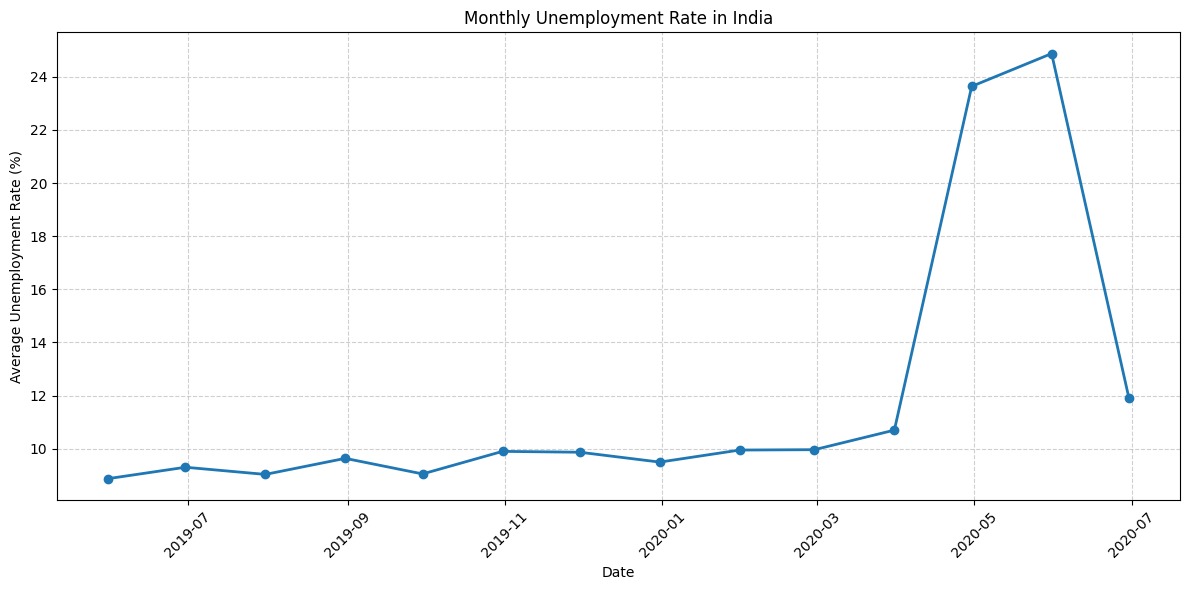

In [8]:

monthly_unemployment = (
    df1.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


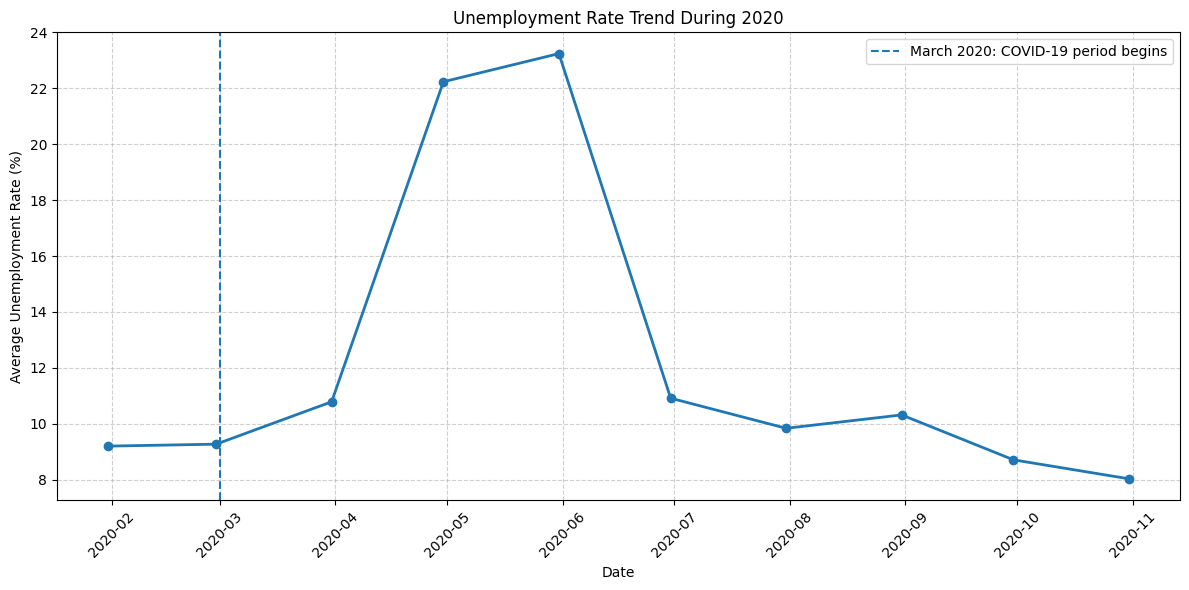

In [9]:

# Calculate average unemployment rate by month
covid_trend = (
    df2.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

# Plot the trend for Dataset 2
plt.figure(figsize=(12, 6))
plt.plot(
    covid_trend.index,
    covid_trend.values,
    marker="o",
    linewidth=2
)

plt.axvline(
    pd.Timestamp("2020-03-01"),
    linestyle="--",
    label="March 2020: COVID-19 period begins"
)

plt.title("Unemployment Rate Trend During 2020")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [10]:

# Find the month with the highest average unemployment rate
highest_month = covid_trend.idxmax()
highest_rate = covid_trend.max()

# Find the month with the lowest average unemployment rate
lowest_month = covid_trend.idxmin()
lowest_rate = covid_trend.min()

print("COVID-19 Period Analysis")
print("-" * 35)

print("Highest average unemployment rate:")
print("Month:", highest_month.strftime("%B %Y"))
print("Rate:", round(highest_rate, 2), "%")

print("\nLowest average unemployment rate:")
print("Month:", lowest_month.strftime("%B %Y"))
print("Rate:", round(lowest_rate, 2), "%")

print("\nMonthly average unemployment rates:")
print(covid_trend.round(2))


COVID-19 Period Analysis
-----------------------------------
Highest average unemployment rate:
Month: May 2020
Rate: 23.24 %

Lowest average unemployment rate:
Month: October 2020
Rate: 8.03 %

Monthly average unemployment rates:
Date
2020-01-31     9.20
2020-02-29     9.27
2020-03-31    10.78
2020-04-30    22.24
2020-05-31    23.24
2020-06-30    10.91
2020-07-31     9.83
2020-08-31    10.31
2020-09-30     8.71
2020-10-31     8.03
Name: Estimated Unemployment Rate (%), dtype: float64


Average Unemployment Rate by Area:
Area
Urban    13.17
Rural    10.32
Name: Estimated Unemployment Rate (%), dtype: float64


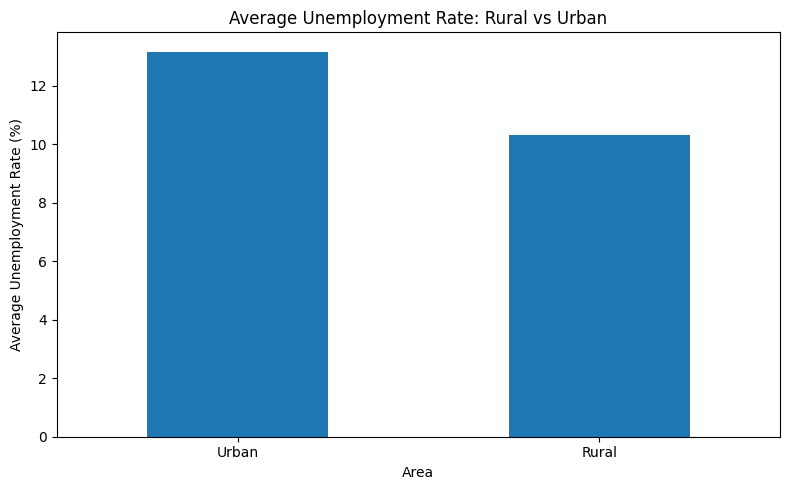

In [11]:

area_unemployment = (
    df1.groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by Area:")
print(area_unemployment.round(2))

plt.figure(figsize=(8, 5))
area_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:

# Compare January-February with March-November 2020
df2["Period"] = df2["Date"].apply(
    lambda date: "Before COVID-19 comparison (Jan-Feb)"
    if date < pd.Timestamp("2020-03-01")
    else "COVID-19 period (Mar-Nov)"
)

period_comparison = (
    df2.groupby("Period")["Estimated Unemployment Rate (%)"]
    .mean()
)

print("Average Unemployment Rate by Period")
print(period_comparison.round(2))

before = period_comparison["Before COVID-19 comparison (Jan-Feb)"]
during = period_comparison["COVID-19 period (Mar-Nov)"]

print("\nDifference in percentage points:", round(during - before, 2))

if before != 0:
    print("Percentage change:", round(((during - before) / before) * 100, 2), "%")


Average Unemployment Rate by Period
Period
Before COVID-19 comparison (Jan-Feb)     9.23
COVID-19 period (Mar-Nov)               12.96
Name: Estimated Unemployment Rate (%), dtype: float64

Difference in percentage points: 3.73
Percentage change: 40.43 %
